# 02 · Regresión lineal simple y múltiple (EA2)

Objetivo: estimar `admission_deposit`. Usa el CSV procesado (`data/processed/`) y la lógica de `src/models/train_regression.py`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "config.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))  # permite `import src...` sin rutas absolutas

import pandas as pd
pd.set_option("display.max_columns", 30)
from src import config
import matplotlib.pyplot as plt
import seaborn as sns
from src.models.train_regression import run_simple_regression, run_multiple_regression
from src.utils.reporter import save_json

## 1. Datos procesados (antes de modelar)

In [2]:
df = pd.read_csv(config.PROCESSED_CSV)
print(df.shape)
df[["admission_deposit", "stay_in_days", "visitors_with_patient", "available_extra_rooms_in_hospital",
    "age_midpoint", "insurance", "severity_of_illness"]].describe(include="all").T

(100000, 14)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
admission_deposit,100000.0,NaN,NaN,NaN,4727.771343,1049.783044,1747.378405,4076.636624,4627.032634,5098.781698,10104.72639
stay_in_days,100000.0,NaN,NaN,NaN,12.3756,7.925432,3.0,8.0,9.0,11.0,49.0
visitors_with_patient,100000.0,NaN,NaN,NaN,3.54506,2.237177,0.0,2.0,3.0,4.0,32.0
available_extra_rooms_in_hospital,100000.0,NaN,NaN,NaN,3.65194,2.719259,0.0,2.0,3.0,4.0,24.0
age_midpoint,100000.0,NaN,NaN,NaN,36.79438,16.267948,5.0,25.5,35.5,45.5,95.5
insurance,100000,2,Yes,78640,NaN,NaN,NaN,NaN,NaN,NaN,NaN
severity_of_illness,100000,3,Moderate,56067,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Regresión lineal simple
**Pregunta:** ¿se puede estimar el depósito de admisión solo con los días de estadía?
**Objetivo:** `admission_deposit` · **Predictora:** `stay_in_days`.

**Configuración:** `LinearRegression()` con parámetros predeterminados dentro de un `Pipeline` (imputador por mediana + modelo); división 80/20 con `random_state=42`. Los pasos que aprenden (imputación) se ajustan solo con el conjunto de entrenamiento.

In [3]:
simple = run_simple_regression(df)
res_s = simple.results
display(pd.Series(res_s["metrics"], name="valor").to_frame())
print("Intercepto:", round(res_s["intercept"], 4), "| Coeficientes:", res_s["coefficients"])
print("\n".join(res_s["interpretation"]))

,valor
MAE,749.730264
RMSE,1039.536404
R2,0.001301
MAE_baseline_media,750.352265


Intercepto: 4662.4261 | Coeficientes: {'stay_in_days': 5.419333174997919}
MAE=749.73: error absoluto medio de la predicción del depósito en el conjunto de prueba.
RMSE=1,039.54: error cuadrático medio (penaliza más los errores grandes).
R²=0.0013: proporción de la varianza del depósito explicada por el modelo.
Referencia: predecir siempre la media de entrenamiento da MAE=750.35; el modelo mejora esa referencia solo de forma marginal (<2 %).
Intercepto: con todas las variables predictoras en 0 el depósito estimado sería 4,662.43 (referencia matemática; puede no ser un caso realista).
stay_in_days: cada día adicional de estadía aumenta el depósito estimado en 5.42 unidades.


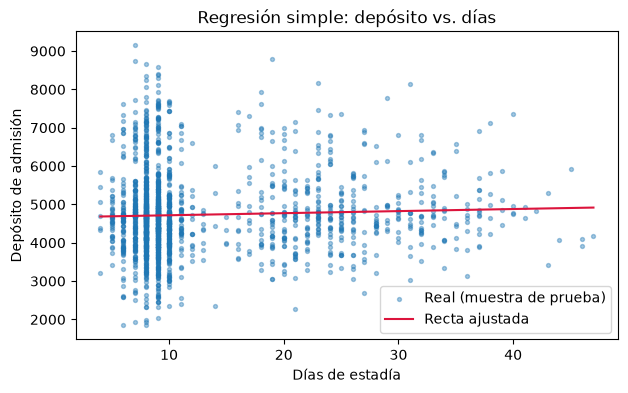

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
muestra = simple.X_test.assign(y=simple.y_test, pred=simple.y_pred).sample(2000, random_state=42)
ax.scatter(muestra["stay_in_days"], muestra["y"], s=8, alpha=0.4, label="Real (muestra de prueba)")
orden = muestra.sort_values("stay_in_days")
ax.plot(orden["stay_in_days"], orden["pred"], color="crimson", label="Recta ajustada")
ax.set(xlabel="Días de estadía", ylabel="Depósito de admisión", title="Regresión simple: depósito vs. días")
ax.legend(); plt.show()

**Lectura:** la métrica clave es R². Si es cercano a 0, los días de estadía casi no explican el depósito: la relación lineal es muy débil en estos datos. El coeficiente indica el cambio estimado del depósito por cada día adicional.

## 3. Regresión lineal múltiple
**Pregunta:** ¿cómo influyen factores clínicos (severidad, edad), logísticos (habitaciones libres) y administrativos (seguro, estadía, visitantes) en el depósito?

**Predictoras:** numéricas `stay_in_days`, `visitors_with_patient`, `available_extra_rooms_in_hospital`, `age_midpoint`; categóricas codificadas `insurance` (No=1, Yes=2) y `severity_of_illness` (Minor=1, Moderate=2, Extreme=3). No se escalan para que los coeficientes conserven sus unidades originales.

In [5]:
multiple = run_multiple_regression(df)
res_m = multiple.results
display(pd.Series(res_m["metrics"], name="valor").to_frame())
coef = pd.Series(res_m["coefficients"], name="coeficiente").to_frame()
coef.loc["(intercepto)"] = res_m["intercept"]
display(coef)

,valor
MAE,746.989653
RMSE,1035.867997
R2,0.008337
MAE_baseline_media,750.352265


,coeficiente
stay_in_days,6.815311
visitors_with_patient,-31.035356
available_extra_rooms_in_hospital,-18.046829
age_midpoint,-0.901092
insurance,16.502992
severity_of_illness,-34.034510
(intercepto),4889.932495


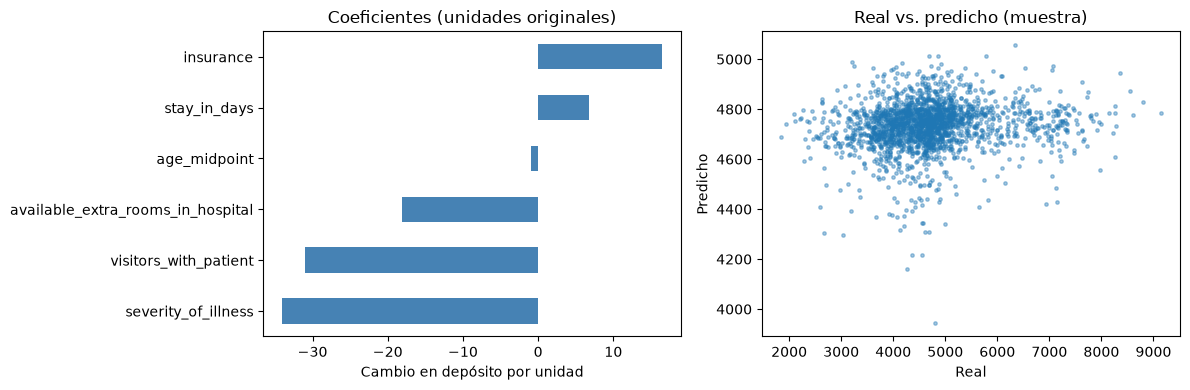

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
coef.drop("(intercepto)")["coeficiente"].sort_values().plot.barh(ax=axes[0], color="steelblue")
axes[0].set(title="Coeficientes (unidades originales)", xlabel="Cambio en depósito por unidad")
axes[1].scatter(multiple.y_test.sample(2000, random_state=1), pd.Series(multiple.y_pred, index=multiple.y_test.index).loc[multiple.y_test.sample(2000, random_state=1).index], s=6, alpha=0.4)
axes[1].set(title="Real vs. predicho (muestra)", xlabel="Real", ylabel="Predicho")
plt.tight_layout(); plt.show()

In [7]:
print("\n".join(res_m["interpretation"]))
print("\nLimitaciones:")
print("\n".join("- " + l for l in res_m["limitations"]))

MAE=746.99: error absoluto medio de la predicción del depósito en el conjunto de prueba.
RMSE=1,035.87: error cuadrático medio (penaliza más los errores grandes).
R²=0.0083: proporción de la varianza del depósito explicada por el modelo.
Referencia: predecir siempre la media de entrenamiento da MAE=750.35; el modelo mejora esa referencia solo de forma marginal (<2 %).
Intercepto: con todas las variables predictoras en 0 el depósito estimado sería 4,889.93 (referencia matemática; puede no ser un caso realista).
stay_in_days: cada día adicional de estadía aumenta el depósito estimado en 6.82 unidades, manteniendo constantes las demás variables.
visitors_with_patient: cada visitante adicional reduce el depósito estimado en 31.04 unidades, manteniendo constantes las demás variables.
available_extra_rooms_in_hospital: cada habitación libre adicional reduce el depósito estimado en 18.05 unidades, manteniendo constantes las demás variables.
age_midpoint: cada año adicional de edad (punto medi

## 4. Comparación y cierre
Se comparan MAE, RMSE y R² de ambos modelos y se guardan los resultados estructurados en `reports/regression-results.json` (modelos en `models/`).

In [8]:
comparacion = pd.DataFrame({"simple": res_s["metrics"], "múltiple": res_m["metrics"]})
display(comparacion)
save_json({"simple": res_s, "multiple": res_m}, config.REGRESSION_RESULTS_JSON)
print("Guardado:", config.REGRESSION_RESULTS_JSON.relative_to(ROOT))

,simple,múltiple
MAE,749.730264,746.989653
RMSE,1039.536404,1035.867997
R2,0.001301,0.008337
MAE_baseline_media,750.352265,750.352265


Guardado: reports\regression-results.json


**Interpretación general:** añadir variables mejora ligeramente las métricas respecto al modelo simple, pero un R² bajo indica que el depósito depende de factores que no están en el dataset o de relaciones no lineales. Los coeficientes son asociaciones (no causalidad) y asumen linealidad y efectos aditivos; la severidad ordinal supone saltos equidistantes.